# Moon phase systematics check
Functions take `(sn_name, band_entries)`. Each plot has its own short run cell below it — edit `sn_name` there and re-run just that cell to check a different candidate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
from scipy.stats import chi2

from periodicity_tools import (
    get_decline_detections,
    analyze_candidate,
    compute_delta_chi2_curve,
    get_moon_illumination_fraction,
    get_moon_altitude_deg,
)

EPOCH_AFTER_PEAK = 1000
POLY_DEG = 3
N_PHASE_BINS = 30  # matches n_phase_bins used in plot_with_phase()
TNS_FILENAME = "tables/tns_public_objects_until_20250916.csv"

# Mean synodic month and a reference new-moon epoch (2000-01-06 18:14 UTC), used only
# to fold time onto a linear lunar phase / mark full-Moon dates. This is an average-
# period approximation, accurate to ~hours (real synodic months vary by up to ~7h from
# the mean) -- NOT used for the actual illumination fractions plotted everywhere else,
# which come from exact ephemeris (get_moon_illumination_fraction).
SYNODIC_MONTH = 29.530588853
JD_REF_NEW_MOON = 2451550.26

band_colors = {1: "g", 2: "r", 3: "orange"}
band_str = {1: "g-band", 2: "r-band", 3: "i-band"}

tns = pd.read_csv(TNS_FILENAME, header=0)

## Load a candidate + summary

In [2]:
def load_band_entries(sn_name, epoch_after_peak=EPOCH_AFTER_PEAK, poly_deg=POLY_DEG):
    discovery_jd = Time(tns.loc[tns["name"] == sn_name, "discoverydate"].iloc[0]).jd
    decline_points = get_decline_detections(sn_name, epoch_after_peak=epoch_after_peak)

    band_entries = []
    for fid in [1, 2, 3]:
        band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
        if len(band_data) < 5:
            continue

        jd = np.array([p["jd"] for p in band_data])
        mag = np.array([p["magpsf"] for p in band_data])
        err = np.array([p["sigmapsf"] for p in band_data])
        days = jd - jd[0]  # days since peak, matches candidate_library convention

        res = analyze_candidate(sn_name, days, mag, err, poly_deg=poly_deg)
        residuals = mag - res["poly_model"](days)

        moon_frac = get_moon_illumination_fraction(jd)
        moon_alt = get_moon_altitude_deg(jd)  # at Palomar
        moon_up = moon_alt > 0
        lunar_phase = ((jd - JD_REF_NEW_MOON) / SYNODIC_MONTH) % 1.0

        band_entries.append({
            "fid": fid, "jd": jd, "days": days, "mag": mag, "err": err,
            "res": res, "residuals": residuals,
            "moon_frac": moon_frac, "moon_alt": moon_alt, "moon_up": moon_up,
            "lunar_phase": lunar_phase,
        })
    return band_entries, discovery_jd


def print_summary(sn_name, band_entries, discovery_jd):
    print(f"=== {sn_name} (discovery JD {discovery_jd:.2f}) ===")
    for e in band_entries:
        n_up = np.sum(e["moon_up"])
        print(f"  {band_str[e['fid']]}: {len(e['jd'])} points, "
              f"peak JD={e['jd'][0]:.2f} ({e['jd'][0] - discovery_jd:.1f} d after discovery), "
              f"best_period={e['res']['best_period']:.2f} d, "
              f"best_amplitude={e['res']['best_amplitude']:.4f} mag | "
              f"Moon above horizon for {n_up}/{len(e['jd'])} points "
              f"({100 * n_up / len(e['jd']):.0f}%)")

In [3]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
print_summary(sn_name, band_entries, discovery_jd)

=== 2020sgf (discovery JD 2459089.95) ===
  g-band: 82 points, peak JD=2459134.88 (44.9 d after discovery), best_period=30.17 d, best_amplitude=0.1961 mag | Moon above horizon for 31/82 points (38%)
  r-band: 100 points, peak JD=2459131.94 (42.0 d after discovery), best_period=35.94 d, best_amplitude=0.1151 mag | Moon above horizon for 43/100 points (43%)


## Amplitude cross-check (poly3-poly6)

In [4]:
def print_amplitude_table(sn_name, band_entries, poly_degs=(3, 4, 5, 6)):
    print(f"{'method':<8}{'band':<8}{'period[d]':<11}{'amplitude[mag]':<16}{'peak-to-trough[mag]':<20}")
    for deg in poly_degs:
        for e in band_entries:
            r = analyze_candidate(sn_name, e["days"], e["mag"], e["err"], poly_deg=deg)
            band = band_str[e["fid"]]
            print(f"poly{deg:<4}{band:<8}{r['best_period']:<11.2f}"
                  f"{r['best_amplitude']:<16.4f}{2 * r['best_amplitude']:<20.4f}")

In [5]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
print_amplitude_table(sn_name, band_entries)

method  band    period[d]  amplitude[mag]  peak-to-trough[mag] 
poly3   g-band  30.17      0.1961          0.3921              
poly3   r-band  35.94      0.1151          0.2302              
poly4   g-band  30.17      0.1928          0.3855              
poly4   r-band  64.70      0.1091          0.2182              
poly5   g-band  28.94      0.1539          0.3079              
poly5   r-band  29.41      0.0814          0.1628              
poly6   g-band  28.94      0.1420          0.2839              
poly6   r-band  29.41      0.0748          0.1497              


In [6]:
def weighted_bin(x, y, err, bin_edges):
    """Weighted-mean bin of y(x); x-position is the weighted mean of the x-values
    actually inside the bin, not the bin's geometric center."""
    xs, means, sems = [], [], []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (x >= lo) & (x < hi if hi < bin_edges[-1] else x <= hi)
        if not np.any(in_bin):
            continue
        weights = 1.0 / err[in_bin] ** 2
        xs.append(np.average(x[in_bin], weights=weights))
        means.append(np.average(y[in_bin], weights=weights))
        sems.append(np.sqrt(1.0 / np.sum(weights)))
    return np.array(xs), np.array(means), np.array(sems)


def fit_sinusoid(phase, residuals, errs):
    """Weighted least-squares fit of residuals = A*sin(2*pi*phase) + B*cos(2*pi*phase)."""
    design = np.column_stack([np.sin(2 * np.pi * phase), np.cos(2 * np.pi * phase)])
    w = 1.0 / errs
    coeffs, *_ = np.linalg.lstsq(design * w[:, None], residuals * w, rcond=None)
    A, B = coeffs
    return A, B, np.hypot(A, B)


def full_moon_days_since(jd0, day_min, day_max):
    """Days-since-jd0 of every full Moon within [day_min, day_max] (mean-synodic-month
    approximation, accurate to ~hours -- see note in the constants cell above)."""
    jd_min, jd_max = jd0 + day_min, jd0 + day_max
    n_min = int(np.floor((jd_min - JD_REF_NEW_MOON) / SYNODIC_MONTH - 0.5))
    n_max = int(np.ceil((jd_max - JD_REF_NEW_MOON) / SYNODIC_MONTH - 0.5))
    out = []
    for n in range(n_min, n_max + 1):
        fm_jd = JD_REF_NEW_MOON + SYNODIC_MONTH * (n + 0.5)
        if jd_min <= fm_jd <= jd_max:
            out.append(fm_jd - jd0)
    return out

## Fold at a custom period
Lists local peaks in each band's periodogram (period, Δχ², p-value), then folds residuals at whatever period you pick -- the band's own best period by default, or any local peak from the list, or any period you type in.

In [7]:
from scipy.signal import find_peaks


def find_periodogram_peaks(sn_name, band_entries, poly_deg=POLY_DEG, period_range=(5, 100),
                            min_grid_separation=3, max_peaks=8):
    for e in band_entries:
        freq, dchi2 = compute_delta_chi2_curve(e["days"], e["mag"], e["err"], poly_deg)
        period = 1 / freq
        order = np.argsort(period)
        period_s, dchi2_s = period[order], dchi2[order]

        in_range = (period_s >= period_range[0]) & (period_s <= period_range[1])
        p_r, d_r = period_s[in_range], dchi2_s[in_range]

        peak_idx, _ = find_peaks(d_r, distance=min_grid_separation)
        peak_idx = peak_idx[np.argsort(d_r[peak_idx])[::-1]][:max_peaks]
        peak_idx = peak_idx[np.argsort(p_r[peak_idx])]  # back to period order for printing

        print(f"{sn_name} {band_str[e['fid']]} (best P={e['res']['best_period']:.2f} d):")
        for idx in peak_idx:
            pval = 1 - chi2.cdf(d_r[idx], df=2)
            print(f"  P={p_r[idx]:.2f} d, Δχ²={d_r[idx]:.2f}, p={pval:.2e}")


def plot_folded_at_period(sn_name, band_entries, period, n_bins=N_PHASE_BINS):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, y, err = e["days"], e["residuals"], e["err"]

        phase = (days % period) / period
        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.65",
                    ecolor="0.75", alpha=0.35, ms=4, label="All residuals", zorder=1)

        bx, by, be = weighted_bin(phase_double, y_double, err_double, np.linspace(0, 2, n_bins + 1))
        ax.errorbar(bx, by, yerr=be, fmt="o", color=color, ecolor=color, ms=6,
                    capsize=2, label="Binned residuals", zorder=3)

        A, B, amp = fit_sinusoid(phase, y, err)
        phase_model = np.linspace(0, 2, 1000)
        ax.plot(phase_model, A * np.sin(2 * np.pi * phase_model) + B * np.cos(2 * np.pi * phase_model),
                color="black", lw=2, label=f"Sinusoid fit at this P (A={amp:.3f} mag)")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.2f} d")
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()

2020sgf g-band (best P=30.17 d):
  P=5.84 d, Δχ²=7.85, p=1.98e-02
  P=6.19 d, Δχ²=5.44, p=6.59e-02
  P=6.66 d, Δχ²=5.21, p=7.37e-02
  P=10.99 d, Δχ²=5.46, p=6.54e-02
  P=17.08 d, Δχ²=10.02, p=6.68e-03
  P=23.24 d, Δχ²=12.85, p=1.62e-03
  P=30.17 d, Δχ²=42.46, p=6.02e-10
  P=36.36 d, Δχ²=34.16, p=3.82e-08
2020sgf r-band (best P=35.94 d):
  P=9.69 d, Δχ²=5.38, p=6.77e-02
  P=11.00 d, Δχ²=10.68, p=4.79e-03
  P=11.98 d, Δχ²=6.03, p=4.92e-02
  P=13.37 d, Δχ²=5.80, p=5.49e-02
  P=24.88 d, Δχ²=15.75, p=3.81e-04
  P=31.71 d, Δχ²=36.82, p=1.01e-08
  P=35.94 d, Δχ²=39.77, p=2.31e-09
  P=55.77 d, Δχ²=39.66, p=2.44e-09


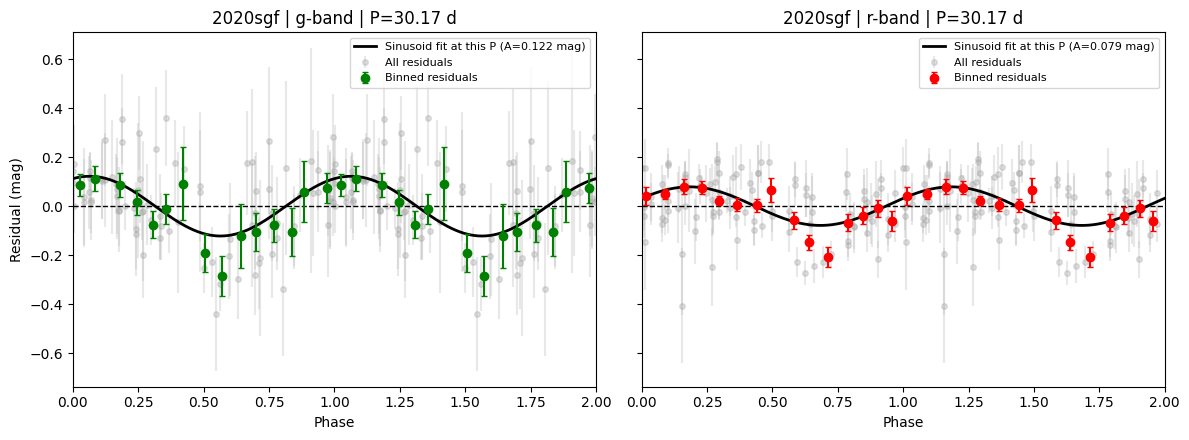

In [8]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
find_periodogram_peaks(sn_name, band_entries)

custom_period = 30.17  # <- change to any period, e.g. one of the local peaks printed above
plot_folded_at_period(sn_name, band_entries, custom_period)

## Folded residuals + Moon illumination, all points
Every raw residual gets its own column at its exact phase (height = effective illumination, 0 if Moon down) — denser/more continuous than binning, no averaging.

In [9]:
def plot_folded_all_points_illum(sn_name, band_entries):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(7 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, y, err, up = e["days"], e["residuals"], e["err"], e["moon_up"]
        moon_frac = e["moon_frac"]
        period = e["res"]["best_period"]

        phase = (days % period) / period
        eff_frac = np.where(up, moon_frac, 0.0)

        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])
        eff_double = np.concatenate([eff_frac, eff_frac])

        ax2 = ax.twinx()
        ax2.vlines(phase_double, 0, eff_double, color="goldenrod", alpha=0.5, lw=2, zorder=1)
        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Effective Moon illum. fraction (per point)")
        ax2.set_zorder(ax.get_zorder() - 1)
        ax.patch.set_visible(False)

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color=color,
                    ecolor=color, alpha=0.7, ms=5, zorder=3, label="Residuals")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase (candidate period)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d")
        ax.legend(fontsize=7, loc="upper right")

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()

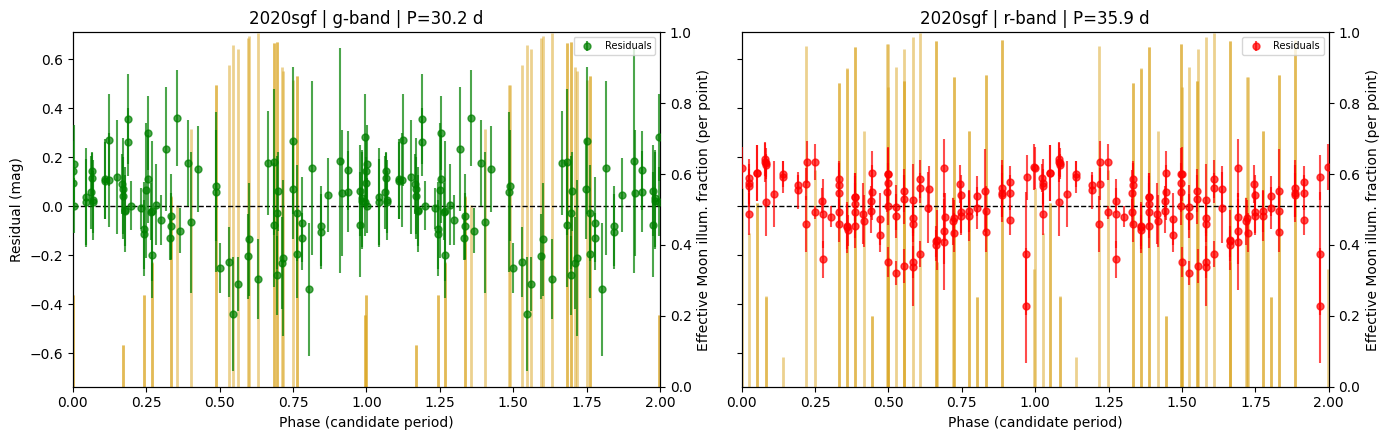

In [10]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
plot_folded_all_points_illum(sn_name, band_entries)


## Folded residuals + Moon illumination, binned
Binned residuals (all points). Bar height = mean illumination among **moon-up points only** in that bin (no bar if a bin has no moon-up point — not shown as 0).

In [11]:
def plot_folded_binned_illum(sn_name, band_entries, n_bins=N_PHASE_BINS):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(7 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, y, err, up = e["days"], e["residuals"], e["err"], e["moon_up"]
        moon_frac = e["moon_frac"]
        period = e["res"]["best_period"]

        phase = (days % period) / period
        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])
        up_double = np.concatenate([up, up])
        frac_double = np.concatenate([moon_frac, moon_frac])

        bin_edges = np.linspace(0, 2, n_bins + 1)
        bin_width = bin_edges[1] - bin_edges[0]
        bar_x, bar_h = [], []
        for lo in bin_edges[:-1]:
            hi = lo + bin_width
            in_bin = (phase_double >= lo) & (phase_double < hi if hi < bin_edges[-1] else phase_double <= hi)
            up_in_bin = up_double[in_bin]
            if np.any(up_in_bin):
                bar_x.append(lo)
                bar_h.append(np.mean(frac_double[in_bin][up_in_bin]))

        ax2 = ax.twinx()
        ax2.bar(bar_x, bar_h, width=bin_width, align="edge", color="goldenrod",
                alpha=0.3, zorder=1, label="Moon illum. (moon-up bins only)")
        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Mean Moon illum. fraction, moon-up bins only")
        ax2.set_zorder(ax.get_zorder() - 1)
        ax.patch.set_visible(False)

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.75",
                    ecolor="0.85", alpha=0.3, ms=4, zorder=2, label="All residuals")

        bx, by, be = weighted_bin(phase_double, y_double, err_double, bin_edges)
        ax.errorbar(bx, by, yerr=be, fmt="o", color=color, ecolor=color, ms=6,
                    zorder=3, label="Binned residuals")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase (candidate period)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d")

        l1, lab1 = ax.get_legend_handles_labels()
        l2, lab2 = ax2.get_legend_handles_labels()
        ax.legend(l1 + l2, lab1 + lab2, fontsize=7, loc="upper right")

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()

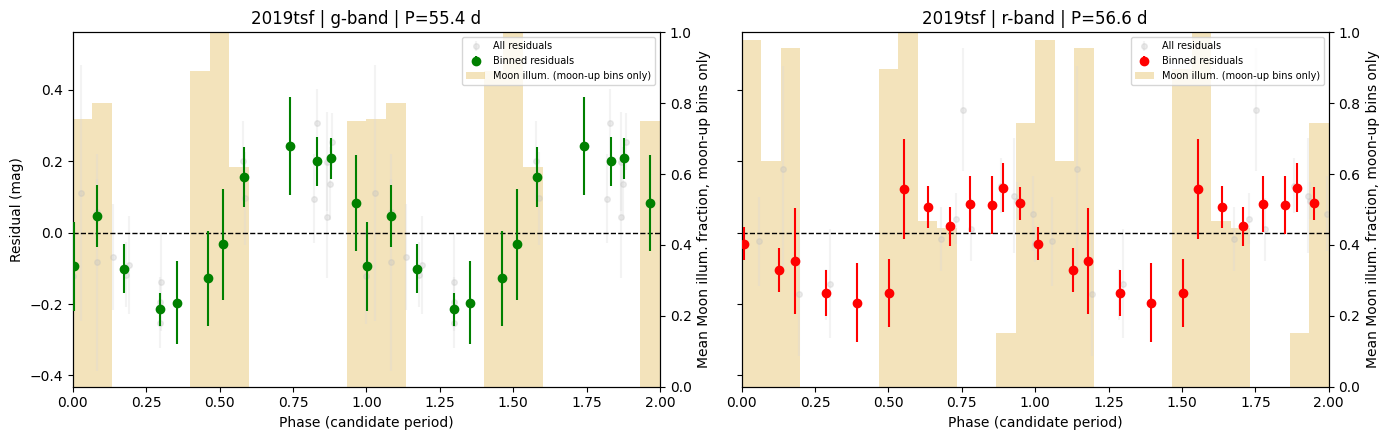

In [12]:
sn_name = "2019tsf"
band_entries, discovery_jd = load_band_entries(sn_name)
plot_folded_binned_illum(sn_name, band_entries)

## Significance of residuals vs. Moon illumination correlation
Significance = r / (1/sqrt(N)) = r*sqrt(N) -- how many "standard units" the correlation is from zero, using that r has spread ~1/sqrt(N) under pure noise.

In [13]:
def print_illum_correlation_significance(sn_name, band_entries):
    for e in band_entries:
        up = e["moon_up"]
        r = np.corrcoef(e["moon_frac"][up], e["residuals"][up])[0, 1]
        n = int(np.sum(up))
        significance = r * np.sqrt(n)  # r compared to 1/sqrt(N), as requested
        print(f"{sn_name} {band_str[e['fid']]}: r={r:.3f} (N={n}), "
              f"r / (1/sqrt(N)) = {significance:.2f}")

2019tsf g-band: r=-0.718 (N=9), r / (1/sqrt(N)) = -2.15
2019tsf r-band: r=-0.111 (N=10), r / (1/sqrt(N)) = -0.35


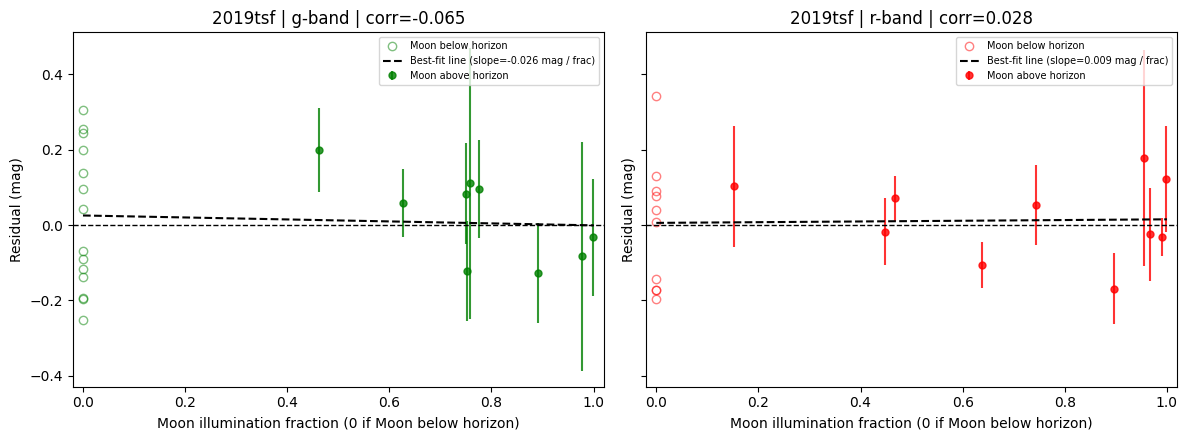

In [14]:
sn_name = "2019tsf"
band_entries, discovery_jd = load_band_entries(sn_name)
print_illum_correlation_significance(sn_name, band_entries)


fig, axes = plt.subplots(1, len(band_entries), figsize=(6 * len(band_entries), 4.5), sharey=True)
axes = np.atleast_1d(axes)

for ax, e in zip(axes, band_entries):
    color = band_colors.get(e["fid"], "k")
    x = np.where(e["moon_up"], e["moon_frac"], 0.0)
    y = e["residuals"]
    err = e["err"]

    ax.plot(x[~e["moon_up"]], y[~e["moon_up"]], "o", mfc="none", mec=color, alpha=0.5, ms=6,
            label="Moon below horizon")
    ax.errorbar(x[e["moon_up"]], y[e["moon_up"]], yerr=err[e["moon_up"]], fmt="o", color=color,
                ecolor=color, alpha=0.8, ms=5, label="Moon above horizon")

    slope, intercept = np.polyfit(x, y, 1)
    xx = np.linspace(0, 1, 200)
    ax.plot(xx, slope * xx + intercept, color="black", lw=1.5, ls="--",
            label=f"Best-fit line (slope={slope:.3f} mag / frac)")

    r = np.corrcoef(x, y)[0, 1]
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_xlim(-0.02, 1.02)
    ax.set_xlabel("Moon illumination fraction (0 if Moon below horizon)")
    ax.set_ylabel("Residual (mag)")
    ax.set_title(f"{sn_name} | {band_str[e['fid']]} | corr={r:.3f}")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

## Bootstrap significance (shuffle test)
Shuffle the residuals relative to the Moon illumination many times (breaking any real pairing), recompute the correlation each time, and see where the real value falls in that shuffled distribution. No distributional assumptions.

In [15]:
def bootstrap_illum_correlation(sn_name, band_entries, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6 * len(band_entries), 4), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        up = e["moon_up"]
        x = e["moon_frac"][up]
        y = e["residuals"][up]
        n = len(x)

        r_real = np.corrcoef(x, y)[0, 1]
        sig_real = r_real * np.sqrt(n)

        boot_sig = np.empty(n_boot)
        for i in range(n_boot):
            y_shuffled = rng.permutation(y)
            r_b = np.corrcoef(x, y_shuffled)[0, 1]
            boot_sig[i] = r_b * np.sqrt(n)

        p_empirical = np.mean(np.abs(boot_sig) >= np.abs(sig_real))

        ax.hist(boot_sig, bins=40, color="0.75", edgecolor="0.4",
                label="Shuffled residuals\n(no real pairing)")
        ax.axvline(sig_real, color="crimson", lw=2, label=f"Real data ({sig_real:.2f})")
        ax.set_xlabel("Significance = r / (1/sqrt(N))")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]}")
        ax.legend(fontsize=7)

        print(f"{sn_name} {band_str[e['fid']]}: real significance={sig_real:.2f}. "
              f"Out of {n_boot} random shuffles, {100 * p_empirical:.2f}% were at "
              f"least this extreme.")

    axes[0].set_ylabel("Count (shuffles)")
    plt.tight_layout()
    plt.show()

2019tsf g-band: real significance=-2.15. Out of 2000 random shuffles, 2.80% were at least this extreme.


2019tsf r-band: real significance=-0.35. Out of 2000 random shuffles, 76.55% were at least this extreme.


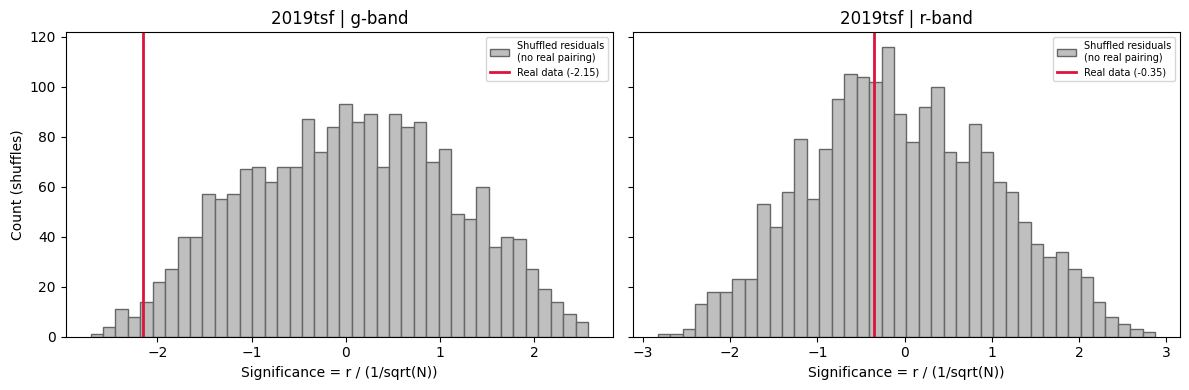

In [16]:
sn_name = "2019tsf"
band_entries, discovery_jd = load_band_entries(sn_name)
bootstrap_illum_correlation(sn_name, band_entries)

## Folded residuals, colored by Moon illumination
Color = mean illumination among moon-up points in that bin only (hollow = no moon-up point in bin). Marker size = number of moon-up points behind the color.

In [17]:
def plot_folded_binned_colored(sn_name, band_entries, n_bins=N_PHASE_BINS, period=None):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(7 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        days, y, err, up = e["days"], e["residuals"], e["err"], e["moon_up"]
        moon_frac = e["moon_frac"]
        this_period = period if period is not None else e["res"]["best_period"]

        phase = (days % this_period) / this_period
        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])
        up_double = np.concatenate([up, up])
        frac_double = np.concatenate([moon_frac, moon_frac])

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.75",
                    ecolor="0.85", alpha=0.35, ms=4, zorder=1, label="All residuals")

        bin_edges = np.linspace(0, 2, n_bins + 1)
        bx, by, be, b_frac_up, b_n_up = [], [], [], [], []
        for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
            in_bin = (phase_double >= lo) & (phase_double < hi if hi < bin_edges[-1] else phase_double <= hi)
            if not np.any(in_bin):
                continue
            w = 1.0 / err_double[in_bin] ** 2
            bx.append(np.average(phase_double[in_bin], weights=w))
            by.append(np.average(y_double[in_bin], weights=w))
            be.append(np.sqrt(1.0 / np.sum(w)))

            n_up = int(np.sum(up_double[in_bin]))
            b_n_up.append(n_up)
            b_frac_up.append(np.mean(frac_double[in_bin][up_double[in_bin]]) if n_up > 0 else np.nan)

        bx, by, be = np.array(bx), np.array(by), np.array(be)
        b_frac_up, b_n_up = np.array(b_frac_up), np.array(b_n_up)
        has_support = ~np.isnan(b_frac_up)

        ax.errorbar(bx, by, yerr=be, fmt="none", ecolor="black", capsize=2, zorder=2)
        ax.scatter(bx[~has_support], by[~has_support], facecolors="none", edgecolors="0.6",
                   s=50, zorder=3, label="No moon-up point in bin")

        sizes = 35 + 20 * b_n_up[has_support]
        sc = ax.scatter(bx[has_support], by[has_support], c=b_frac_up[has_support],
                         cmap="viridis", vmin=0, vmax=1, s=sizes, edgecolor="black",
                         linewidth=0.8, zorder=4,
                         label="Binned residuals (size = # moon-up pts)")

        A, B, amp = fit_sinusoid(phase, y, err)
        phase_model = np.linspace(0, 2, 1000)
        sin_model = A * np.sin(2 * np.pi * phase_model) + B * np.cos(2 * np.pi * phase_model)
        ax.plot(phase_model, sin_model, color="black", lw=2,
                label=f"Sinusoid fit at this P (A={amp:.3f} mag)")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Phase (candidate period)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={this_period:.2f} d")
        ax.legend(fontsize=7)
        plt.colorbar(sc, ax=ax, label="Mean Moon illum. fraction, moon-up points only")

        r = np.corrcoef(b_frac_up[has_support], by[has_support])[0, 1]
        print(f"{sn_name} {band_str[e['fid']]}: correlation (binned residual vs. binned "
              f"moon-up illumination) = {r:.3f} ({np.sum(has_support)}/{len(bx)} bins had "
              f"moon-up support)")

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()

2019tsf g-band: correlation (binned residual vs. binned moon-up illumination) = -0.651 (12/24 bins had moon-up support)
2019tsf r-band: correlation (binned residual vs. binned moon-up illumination) = -0.421 (18/26 bins had moon-up support)


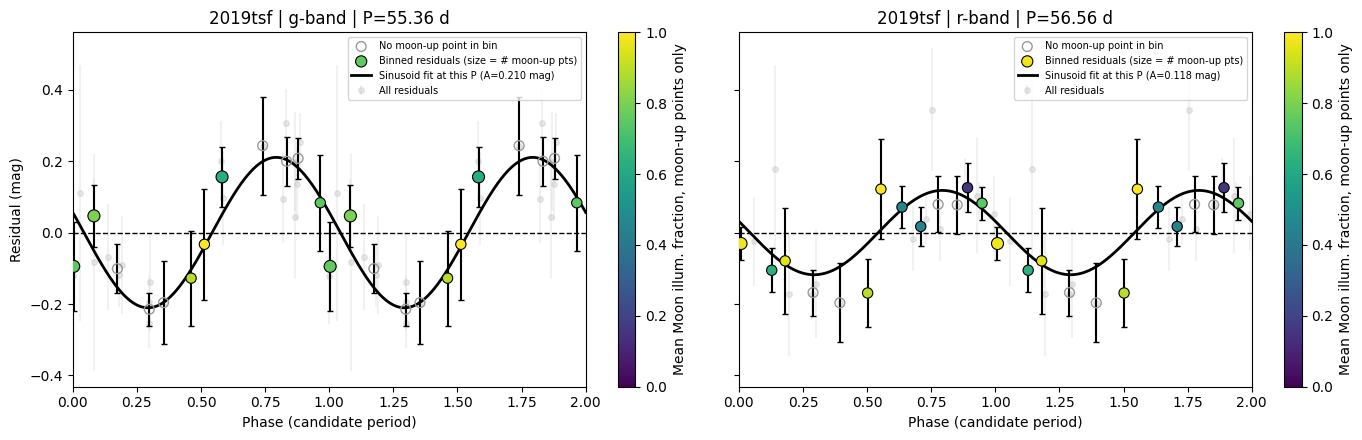

In [18]:
sn_name = "2019tsf"
band_entries, discovery_jd = load_band_entries(sn_name)

custom_period = None  # set to a number (e.g. from find_periodogram_peaks) to override each band's own best period
plot_folded_binned_colored(sn_name, band_entries, period=custom_period)

## Light curve, full-Moon dates marked
The actual light curve (not residuals) + baseline/full-model fit, with full-Moon dates marked.

In [19]:
def plot_light_curve_with_moon(sn_name, band_entries):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(7 * len(band_entries), 4.5))
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, mag, err = e["days"], e["mag"], e["err"]
        jd0 = e["jd"][0]
        period = e["res"]["best_period"]
        poly_model, full_model = e["res"]["poly_model"], e["res"]["full_model"]

        ax.errorbar(days, mag, yerr=err, fmt="o", color=color, ecolor=color,
                    alpha=0.8, ms=5, zorder=3, label="Data")

        t_grid = np.linspace(days.min(), days.max(), 1000)
        ax.plot(t_grid, poly_model(t_grid), color="black", ls="--", lw=2,
                zorder=2, label="Baseline")
        ax.plot(t_grid, full_model(t_grid), color="black", ls="-", lw=2,
                zorder=2, label="Baseline + sinusoid")

        for fm_day in full_moon_days_since(jd0, days.min(), days.max()):
            ax.axvline(fm_day, color="goldenrod", ls=":", lw=1.5, zorder=1)
        ax.plot([], [], color="goldenrod", ls=":", lw=1.5, label="Full Moon")

        ax.invert_yaxis()
        ax.set_xlabel("Days since peak")
        ax.set_ylabel("Magnitude")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]} | P={period:.1f} d")
        ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

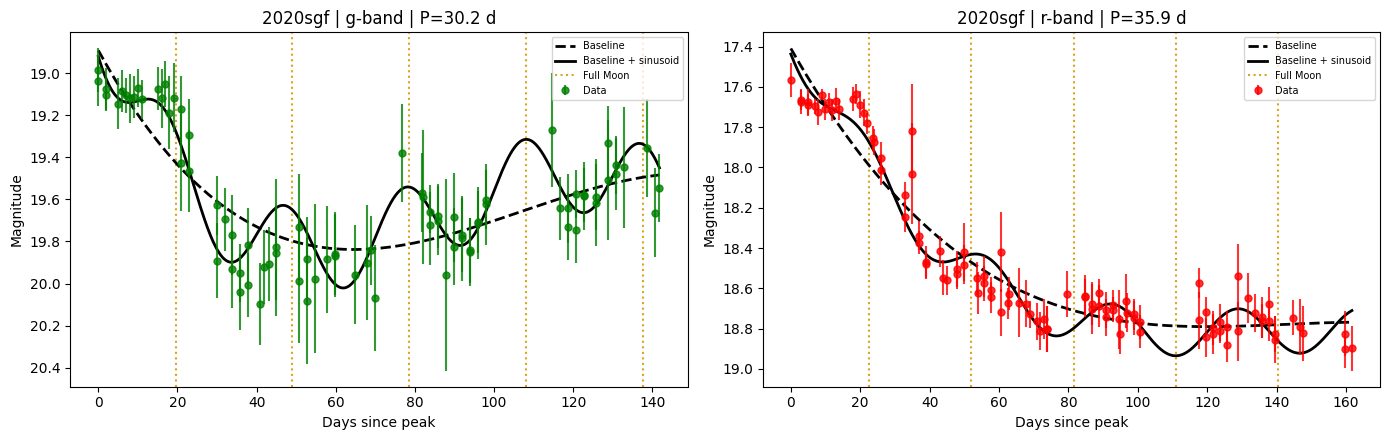

In [20]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
plot_light_curve_with_moon(sn_name, band_entries)

## Residuals vs. time, full-Moon dates marked
Gold lines = full Moon. Top axis = raw illuminated fraction on that date. Hollow, error-bar-free points = Moon below horizon at that exposure.

In [21]:
def plot_time_panel(sn_name, band_entries):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(7 * len(band_entries), 4.5))
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        days, y, err, up = e["days"], e["residuals"], e["err"], e["moon_up"]
        jd0 = e["jd"][0]
        period = e["res"]["best_period"]
        poly_model, full_model = e["res"]["poly_model"], e["res"]["full_model"]

        ax.plot(days[~up], y[~up], "o", mfc="none", mec=color, alpha=0.4, ms=5,
                zorder=2, label="Moon below horizon")
        ax.errorbar(days[up], y[up], yerr=err[up], fmt="o", color=color, ecolor=color,
                    alpha=0.8, ms=5, zorder=3, label="Moon above horizon")

        t_grid = np.linspace(days.min(), days.max(), 1000)
        ax.plot(t_grid, full_model(t_grid) - poly_model(t_grid), color="black", lw=2,
                zorder=4, label=f"Best-fit sinusoid (P={period:.1f} d)")

        for fm_day in full_moon_days_since(jd0, days.min(), days.max()):
            ax.axvline(fm_day, color="goldenrod", ls=":", lw=1.5, zorder=1)
        ax.plot([], [], color="goldenrod", ls=":", lw=1.5, label="Full Moon")

        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlabel("Days since peak")
        ax.set_ylabel("Residual (mag)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]}")
        ax.legend(fontsize=7)

        ax2 = ax.twiny()
        ax2.set_xlim(ax.get_xlim())
        ticks = np.array([t for t in ax.get_xticks() if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]])
        fracs = get_moon_illumination_fraction(jd0 + ticks)
        ax2.set_xticks(ticks)
        ax2.set_xticklabels([f"{f:.2f}" for f in fracs])
        ax2.set_xlabel("Moon illuminated fraction on that date")

    plt.tight_layout()
    plt.show()

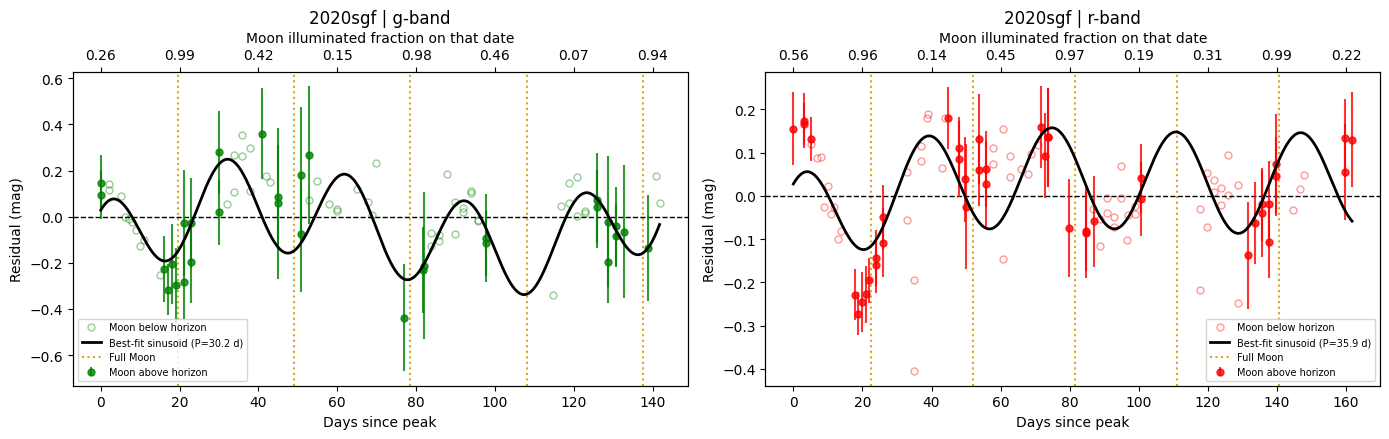

In [22]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
plot_time_panel(sn_name, band_entries)

## Residuals vs. lunar synodic phase
Linear-in-time fold (0/1/2=new, 0.5/1.5=full), foldable like the SN's own phase. Sinusoid amplitude here is a real amplitude at the lunar period. Significance is read off the same Δχ² grid as everywhere else in the pipeline, at the frequency nearest the synodic month.

In [23]:
def plot_lunar_phase_panel(sn_name, band_entries, n_bins=N_PHASE_BINS):
    fig, axes = plt.subplots(1, len(band_entries), figsize=(6 * len(band_entries), 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, e in zip(axes, band_entries):
        color = band_colors.get(e["fid"], "k")
        phase = e["lunar_phase"]
        y, err = e["residuals"], e["err"]

        phase_double = np.concatenate([phase, phase + 1])
        y_double = np.concatenate([y, y])
        err_double = np.concatenate([err, err])

        ax.errorbar(phase_double, y_double, yerr=err_double, fmt="o", color="0.65",
                    ecolor="0.75", alpha=0.35, ms=4, label="All residuals", zorder=1)

        bx, by, be = weighted_bin(phase_double, y_double, err_double, np.linspace(0, 2, n_bins + 1))
        ax.errorbar(bx, by, yerr=be, fmt="o", color=color, ecolor=color, ms=6,
                    capsize=2, label="Binned residuals", zorder=3)

        A, B, amp = fit_sinusoid(phase, y, err)
        phase_model = np.linspace(0, 2, 1000)
        ax.plot(phase_model, A * np.sin(2 * np.pi * phase_model) + B * np.cos(2 * np.pi * phase_model),
                color="k", lw=2, label=f"Best-fit sinusoid at lunar period (A={amp:.3f} mag)")

        ax.axvline(0.5, color="grey", ls=":", lw=1)
        ax.axvline(1.5, color="grey", ls=":", lw=1)
        ax.axhline(0, color="black", ls="--", lw=1)
        ax.set_xlim(0, 2)
        ax.set_xlabel("Lunar synodic phase (0/1/2=new, 0.5/1.5=full)")
        ax.set_title(f"{sn_name} | {band_str[e['fid']]}")
        ax.legend(fontsize=8)

        r = np.corrcoef(phase, y)[0, 1]
        print(f"{sn_name} {band_str[e['fid']]}: correlation (vs. lunar phase)={r:.3f}, "
              f"sinusoid A={amp:.4f} mag at P=synodic month (N={len(y)})")

    axes[0].set_ylabel("Residual (mag)")
    plt.tight_layout()
    plt.show()


def print_lunar_significance(sn_name, band_entries, poly_deg=POLY_DEG):
    synodic_freq = 1 / SYNODIC_MONTH
    for e in band_entries:
        freq, dchi2 = compute_delta_chi2_curve(e["days"], e["mag"], e["err"], poly_deg=poly_deg)
        idx = np.argmin(np.abs(freq - synodic_freq))
        dchi2_lunar = dchi2[idx]
        p_lunar = 1 - chi2.cdf(dchi2_lunar, df=2)

        print(f"{sn_name} {band_str[e['fid']]}: nearest grid freq={freq[idx]:.5f} "
              f"(P={1 / freq[idx]:.2f} d) to synodic freq={synodic_freq:.5f} "
              f"(P={SYNODIC_MONTH:.2f} d) | Δχ²={dchi2_lunar:.2f}, p-value={p_lunar:.2e} "
              f"(candidate's own best: Δχ²={e['res']['delta_chi2']:.2f}, "
              f"p-value={e['res']['p_value_single_freq']:.2e})")

2020sgf g-band: correlation (vs. lunar phase)=0.026, sinusoid A=0.1210 mag at P=synodic month (N=82)
2020sgf r-band: correlation (vs. lunar phase)=-0.033, sinusoid A=0.0694 mag at P=synodic month (N=100)


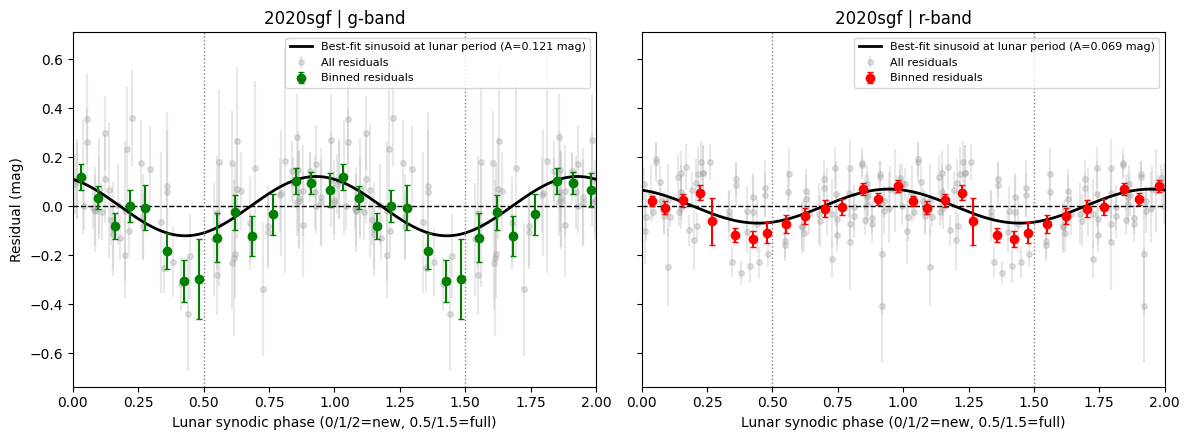

2020sgf g-band: nearest grid freq=0.03456 (P=28.94 d) to synodic freq=0.03386 (P=29.53 d) | Δχ²=37.35, p-value=7.75e-09 (candidate's own best: Δχ²=42.46, p-value=6.02e-10)
2020sgf r-band: nearest grid freq=0.03401 (P=29.41 d) to synodic freq=0.03386 (P=29.53 d) | Δχ²=26.03, p-value=2.22e-06 (candidate's own best: Δχ²=39.77, p-value=2.31e-09)


In [24]:
sn_name = "2020sgf"
band_entries, discovery_jd = load_band_entries(sn_name)
plot_lunar_phase_panel(sn_name, band_entries)
print_lunar_significance(sn_name, band_entries)

## Average periodogram across the dual-band sample
Builds the same 34 dual-band candidates used in `periodicity_search.ipynb` (same cuts: z<=0.05, dec>-60, Ibc-like types, >=20 detections/band), computes each one's own Δχ² periodogram, regrids to a common period grid (candidates with short baselines simply don't cover the long-period end), and averages. **Caveat:** periodogram Δχ² is known to trend upward at longer trial periods for reasons unrelated to any real signal (fewer independent cycles sampled, degeneracy between a long-period sinusoid and the low-order polynomial baseline) — so a flat null expectation of ~2 (the mean of a χ²-2dof distribution) is *not* a rigorous baseline here. Read this as "is there a bump *beyond* the generic upward trend", not "is it above 2". The proper null would be the Monte-Carlo simulation discussed earlier, run per candidate.

In [25]:
def build_all_candidates(epoch_after_peak=EPOCH_AFTER_PEAK, min_det=20):
    tns_all = pd.read_csv(TNS_FILENAME, header=0)
    tns_all = tns_all[(tns_all["redshift"] <= 0.05) & (tns_all["declination"] > -60)]
    sn_typeids = [4, 5, 6, 7, 9, 106]
    tns_ibc = tns_all[np.isin(tns_all["typeid"], sn_typeids)]

    per_sn = {}
    for name in tns_ibc["name"]:
        decline_points = get_decline_detections(name, epoch_after_peak=epoch_after_peak)
        bands = {}
        for fid in [1, 2]:
            band_data = [p for p in decline_points if p.get("fid") == fid and "candid" in p]
            if len(band_data) < min_det:
                continue
            jd = np.array([p["jd"] for p in band_data])
            mag = np.array([p["magpsf"] for p in band_data])
            err = np.array([p["sigmapsf"] for p in band_data])
            bands[fid] = (jd - jd[0], mag, err)
        if bands:
            per_sn[name] = bands

    dual_band_names = [name for name, bands in per_sn.items() if {1, 2}.issubset(bands.keys())]
    return per_sn, dual_band_names


def average_periodogram(per_sn, names, period_grid, poly_deg=POLY_DEG):
    all_curves = []
    for name in names:
        band_curves = []
        for fid, (days, mag, err) in per_sn[name].items():
            freq, dchi2 = compute_delta_chi2_curve(days, mag, err, poly_deg)
            period = 1.0 / freq
            order = np.argsort(period)
            p_sorted, d_sorted = period[order], dchi2[order]
            interp = np.interp(period_grid, p_sorted, d_sorted, left=np.nan, right=np.nan)
            valid = (period_grid >= p_sorted.min()) & (period_grid <= p_sorted.max())
            band_curves.append(np.where(valid, interp, np.nan))
        all_curves.append(np.nanmean(np.array(band_curves), axis=0))
    all_curves = np.array(all_curves)
    mean_curve = np.nanmean(all_curves, axis=0)
    n_contrib = np.sum(~np.isnan(all_curves), axis=0)
    return mean_curve, n_contrib, all_curves

In [26]:
def plot_average_periodogram(period_grid, mean_curve, n_contrib, title=""):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(period_grid, mean_curve, color="black", lw=2, label="Mean Δχ² across sample")
    ax.axvline(SYNODIC_MONTH, color="goldenrod", ls=":", lw=1.5, label="Lunar synodic month")
    ax.set_xlabel("Trial period (days)")
    ax.set_ylabel("Mean Δχ²")
    ax.set_title(title)
    ax.legend(fontsize=8)

    ax2 = ax.twinx()
    ax2.plot(period_grid, n_contrib, color="0.6", lw=1, ls="--")
    ax2.set_ylabel("# candidates contributing", color="0.5")
    ax2.tick_params(axis="y", colors="0.5")

    plt.tight_layout()
    plt.show()

34 dual-band candidates


/var/folders/9v/9mgg2nhs31x_zn1r4181_xym0000gn/T/ipykernel_17241/3223076736.py:38: RuntimeWarning: Mean of empty slice
  all_curves.append(np.nanmean(np.array(band_curves), axis=0))


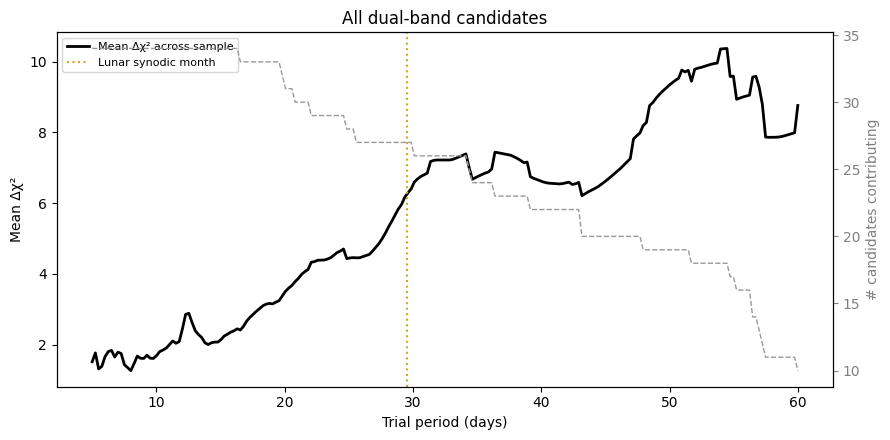

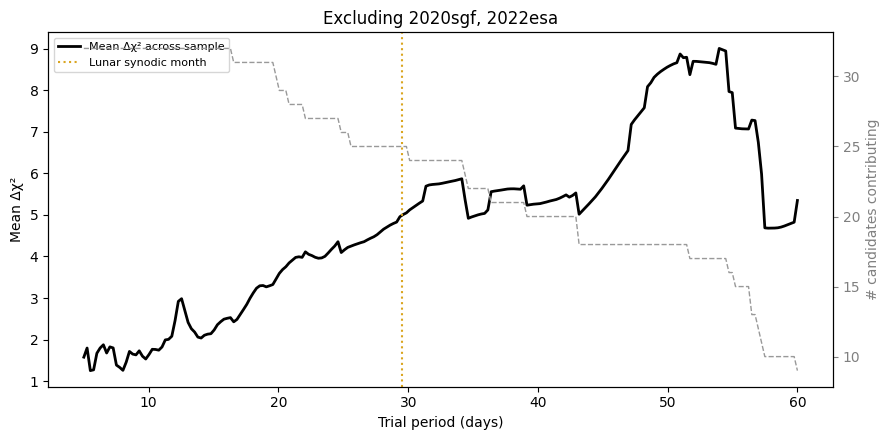

In [27]:
period_grid = np.linspace(5, 60, 220)
per_sn, dual_band_names = build_all_candidates()
print(f"{len(dual_band_names)} dual-band candidates")

mean_curve, n_contrib, _ = average_periodogram(per_sn, dual_band_names, period_grid)
plot_average_periodogram(period_grid, mean_curve, n_contrib, title="All dual-band candidates")

excl_names = [n for n in dual_band_names if n not in ("2020sgf", "2022esa")]
mean_excl, n_excl, _ = average_periodogram(per_sn, excl_names, period_grid)
plot_average_periodogram(period_grid, mean_excl, n_excl, title="Excluding 2020sgf, 2022esa")